In [2]:
from sklearn.datasets import load_iris

In [4]:
iris = load_iris()
x = iris.data
y = iris.target

In [15]:
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [16]:
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


In [13]:
import pandas as pd

pd.DataFrame(x)

,0,1,2,3
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [14]:
pd.DataFrame(y)

,0
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [5]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=41)

In [6]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier()
clf.fit(x_train,y_train)

DecisionTreeClassifier()

In [7]:
y_pred = clf.predict(x_test)

In [8]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

0.9

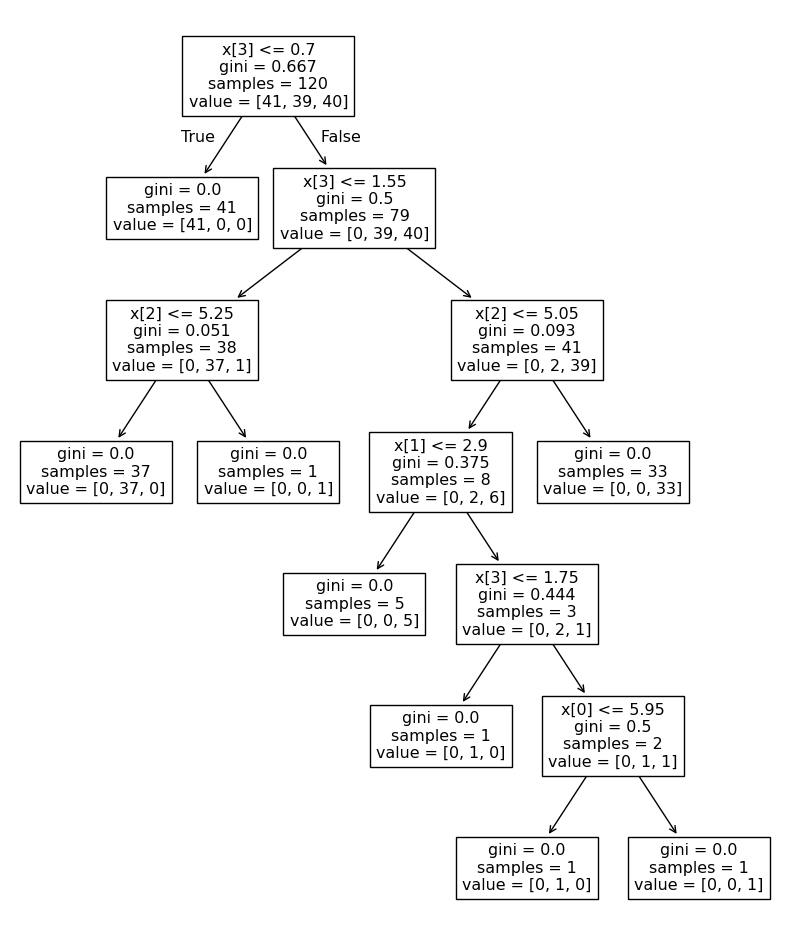

In [12]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(10,12))
plot_tree(clf)
plt.show()

here <br>
x[0] = sepal length <br>
x[1] = sepal width <br>
x[2] = petal length <br>
x[3] = petal width <br>

whose gini = 0.0 are leaf nodes <br>
values = [setosa,versicolor,virginica]

# overfitting and underfitting in decision trees

In [2]:
import pandas as pd

df = pd.read_csv('Social_Network_Ads.csv')
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [3]:
df.columns

Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [4]:
df['Gender'].replace({'Male':0,'Female':1},inplace=True)

/tmp/ipykernel_1980/4071885255.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Gender'].replace({'Male':0,'Female':1},inplace=True)
/tmp/ipykernel_1980/4071885255.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Gender'].replace({'Male':0,'Female':1},inplace=True)


In [5]:
x = df[['Gender','Age','EstimatedSalary']]
y = df['Purchased']

In [6]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=41)

In [7]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier()
clf.fit(x_train,y_train)

DecisionTreeClassifier()

In [8]:
y_pred = clf.predict(x_test)

In [9]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

0.8625

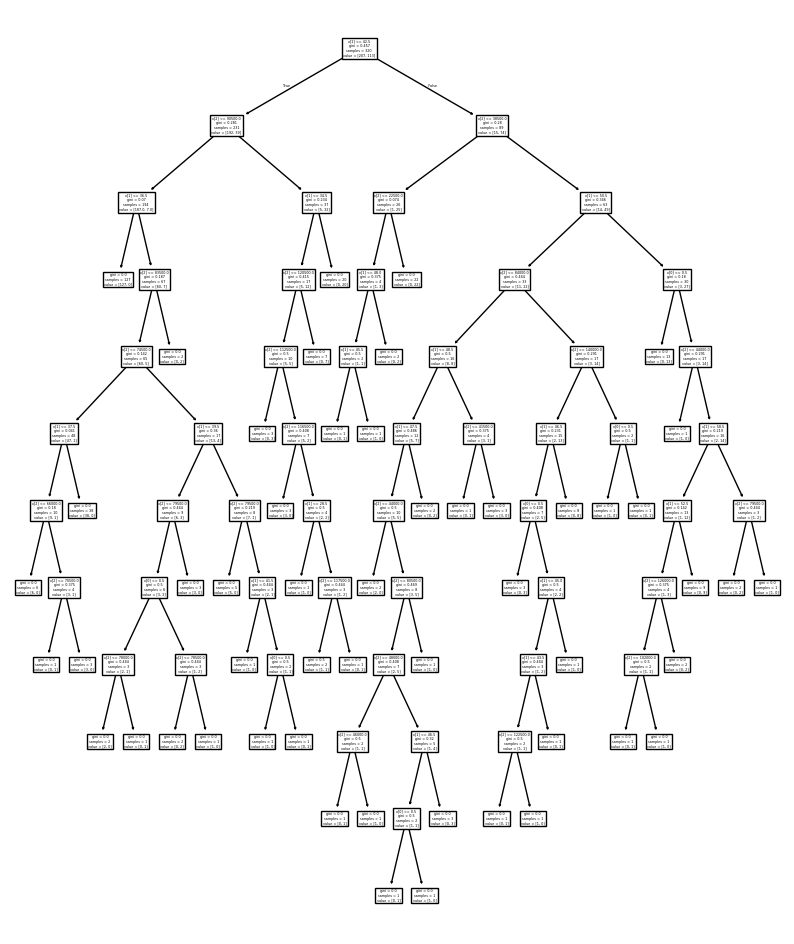

In [10]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(10,12))
plot_tree(clf)
plt.show()

too large of a decision tree , as if model is trying to memorise something , this might result in overfitting

In [11]:
import numpy as np

In [12]:
def analyzer(maximum_depth, x_train, y_train, x, y):
    # Ensure we use numpy arrays for slicing
    x_np = x.values if hasattr(x, 'values') else x
    x_train_np = x_train.values if hasattr(x_train, 'values') else x_train

    clf = DecisionTreeClassifier(max_depth=maximum_depth)
    clf.fit(x_train_np, y_train)

    # We only slice the first two features for plotting
    a = np.arange(start=x_np[:, 1].min() - 1, stop=x_np[:, 1].max() + 1, step=0.1)
    b = np.arange(start=x_np[:, 2].min() - 1, stop=x_np[:, 2].max() + 1, step=100)

    xx, yy = np.meshgrid(a, b)
    input_array = np.array([xx.ravel(), yy.ravel()]).T

    # Temporary classifier fitted only on the 2 features used for plotting
    clf_plot = DecisionTreeClassifier(max_depth=maximum_depth)
    clf_plot.fit(x_train_np[:, [1, 2]], y_train)

    labels = clf_plot.predict(input_array)
    plt.contourf(xx, yy, labels.reshape(xx.shape), alpha=0.5)
    plt.scatter(x_np[:, 1], x_np[:, 2], c=y, edgecolors='k')
    plt.xlabel('Age')
    plt.ylabel('EstimatedSalary')
    plt.show()

overfitting

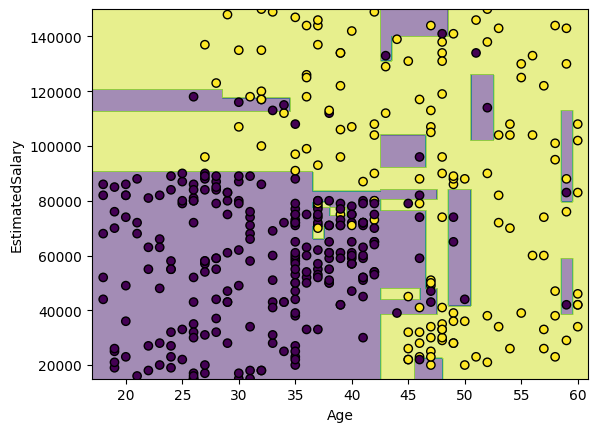

In [13]:
analyzer(None,x_train,y_train,x,y)

underfitting

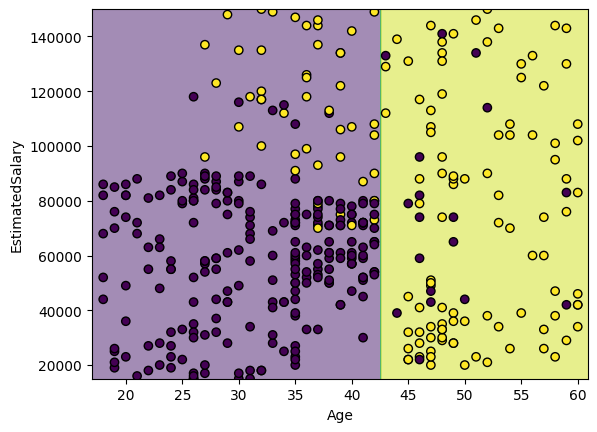

In [14]:
analyzer(1,x_train,y_train,x,y)

looks good

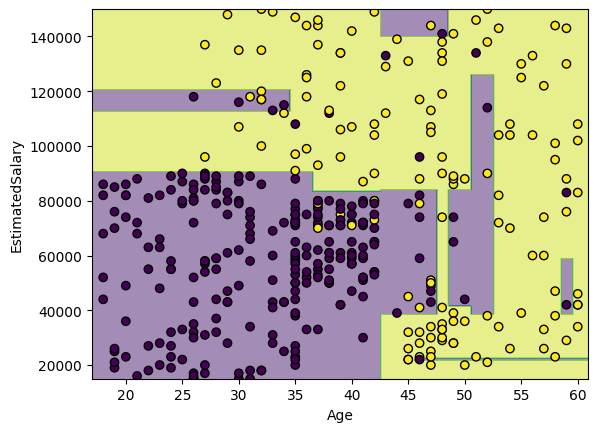

In [15]:
analyzer(6,x_train,y_train,x,y)

lets see accuracy score of it as well as tree structure

In [16]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth = 6)
clf.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=6)

better than earlier one

In [17]:
y_pred = clf.predict(x_test)
accuracy_score(y_test,y_pred)

0.9

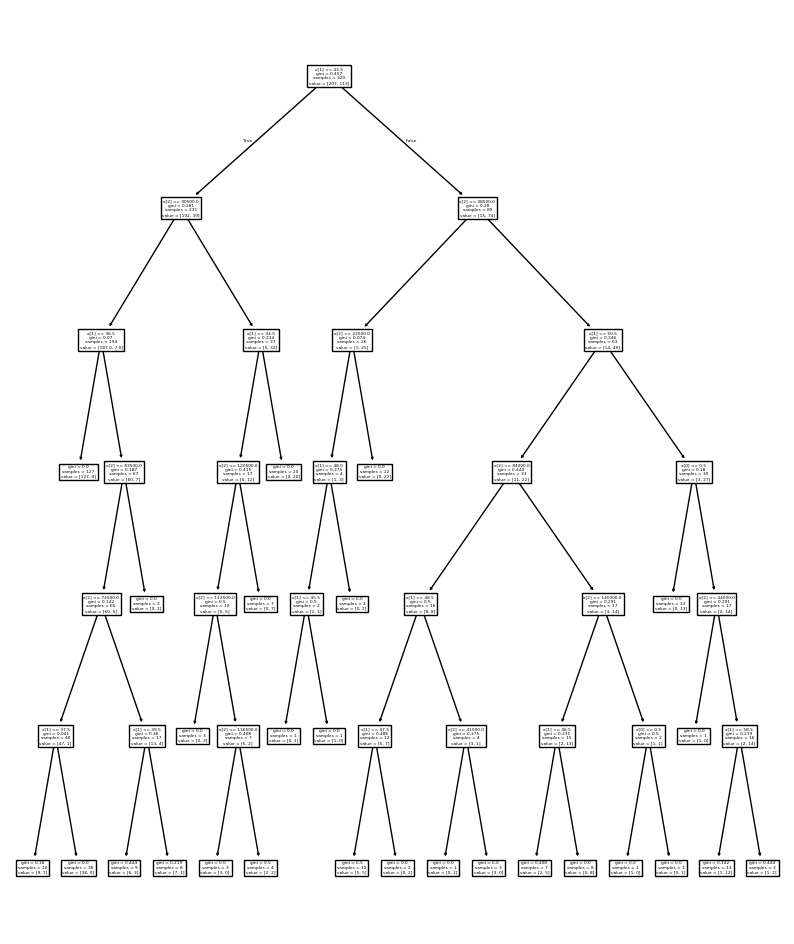

In [18]:
plt.figure(figsize=(10,12))
plot_tree(clf)
plt.show()

we changed from a decision tree of depth 11 to decision tree of depth 6 and increased our accuracy as well

# Hyper-parameter tuning using GridSearchCV

In [19]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x = scaler.fit_transform(x)
x

array([[-1.02020406, -1.78179743, -1.49004624],
       [-1.02020406, -0.25358736, -1.46068138],
       [ 0.98019606, -1.11320552, -0.78528968],
       ...,
       [ 0.98019606,  1.17910958, -1.46068138],
       [-1.02020406, -0.15807423, -1.07893824],
       [ 0.98019606,  1.08359645, -0.99084367]])

In [20]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=41)

In [24]:
clf = DecisionTreeClassifier()
clf.fit(x_train,y_train)

y_pred = clf.predict(x_test)
accuracy_score(y_test,y_pred)

0.8625

In [25]:
param_dist = {
    "criterion" : ["gini","entropy"],
    "max_depth" : [1,2,3,4,5,6,7,None]
}

In [26]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(clf,param_grid=param_dist,cv=10,n_jobs=-1)
grid.fit(x_train,y_train)

GridSearchCV(cv=10, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 2, 3, 4, 5, 6, 7, None]})

In [28]:
print(grid.best_estimator_)

DecisionTreeClassifier(max_depth=2)


In [29]:
print(grid.best_score_)

0.909375


In [30]:
print(grid.best_params_)

{'criterion': 'gini', 'max_depth': 2}
